# 11 · Annotated videos

Visual output of the full pipeline on the external videos: the surfer's skeleton (YOLO26-pose, 17 COCO keypoints), a box colored by the maneuver the timeline reports at that moment, and a timeline bar with a cursor.

The skeleton is illustrative only: the classifier decides from V-JEPA 2 features of the surfer crop, not from the keypoints.

Window labels: one of the 4 maneuvers, **none** (low confidence or surfer not visible) or **unfamiliar** (the k-nearest-neighbor distance check of notebook 10 says the footage looks unlike any training clip).

## 1. Setup

In [1]:
import sys
from pathlib import Path

# Make the project root importable (notebooks/ is one level below it)
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import cv2
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch                      # imported before ultralytics so it is fully initialized first
from ultralytics import YOLO

from src.data.features import load_features
from src.inference.annotate import annotate_video
from src.inference.novelty import KnnNovelty, add_knn_distance
from src.inference.timeline import label_windows, read_video, window_labels
from src.models.encoder import VJEPA2Encoder

splits = pd.read_csv(PROJECT_ROOT / "data" / "splits.csv")
VIDEOS = sorted((PROJECT_ROOT / "data" / "external").glob("pexels_*.mp4"))
OUT_DIR = PROJECT_ROOT / "data" / "external" / "annotated"   # not versioned (data/ is ignored)
OUT_DIR.mkdir(exist_ok=True)

# Same settings as notebook 10
WINDOW_S, STRIDE_S, SAMPLE_FPS = 2.8, 0.7, 12

detector = YOLO("yolo26s.pt")          # person boxes, used for the surfer crop
pose_model = YOLO("yolo26s-pose.pt")   # person boxes + 17 keypoints, used only for drawing
encoder = VJEPA2Encoder()
probe = joblib.load(PROJECT_ROOT / "models" / "linear_probe_surfer.joblib")
classes = list(probe.classes_)
print(len(VIDEOS), "videos |", classes)

c:\Users\fabri\Desktop\Portfolio\surf-maneuver-recognition\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1120 00:27:20.592000 64112 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 587/587 [00:03<00:00, 183.91it/s]


7 videos | ['360', 'cutback-frontside', 'roller', 'take-off']


## 2. Novelty detector

In [2]:
# Same check as notebook 10, now as a reusable object saved for the app
X_surfer = load_features(splits, "vjepa2_vitl_t8_surfer").mean(axis=1)
novelty = KnnNovelty(k=10, quantile=0.95).fit(X_surfer, splits["group"].to_numpy())
joblib.dump(novelty, PROJECT_ROOT / "models" / "knn_novelty.joblib", compress=3)
print(f"threshold {novelty.threshold_:.3f} (notebook 10: 0.059)")

threshold 0.059 (notebook 10: 0.059)


## 3. Annotated videos

In [3]:
for path in VIDEOS:
    frames, fps = read_video(path, SAMPLE_FPS)
    windows = label_windows(frames, fps, WINDOW_S, STRIDE_S, detector, encoder, probe)
    windows = add_knn_distance(windows, novelty)
    labels, confidence = window_labels(windows, classes, novelty_threshold=novelty.threshold_)

    out_path = annotate_video(path, OUT_DIR / f"{path.stem}_annotated.mp4", windows, labels, confidence, pose_model)
    counts = pd.Series(labels).value_counts().to_dict()
    print(f"{path.stem}: {counts} -> {out_path.name}")

pexels_1: {'unfamiliar': 24} -> pexels_1_annotated.mp4
pexels_2: {'unfamiliar': 38} -> pexels_2_annotated.mp4
pexels_3: {'unfamiliar': 24, 'take-off': 3, 'roller': 2} -> pexels_3_annotated.mp4
pexels_4: {'unfamiliar': 12, 'roller': 9, 'take-off': 7, 'cutback-frontside': 1} -> pexels_4_annotated.mp4
pexels_5: {'unfamiliar': 12} -> pexels_5_annotated.mp4
pexels_6: {'unfamiliar': 37} -> pexels_6_annotated.mp4
pexels_7: {'unfamiliar': 40} -> pexels_7_annotated.mp4


## 4. One frame per video

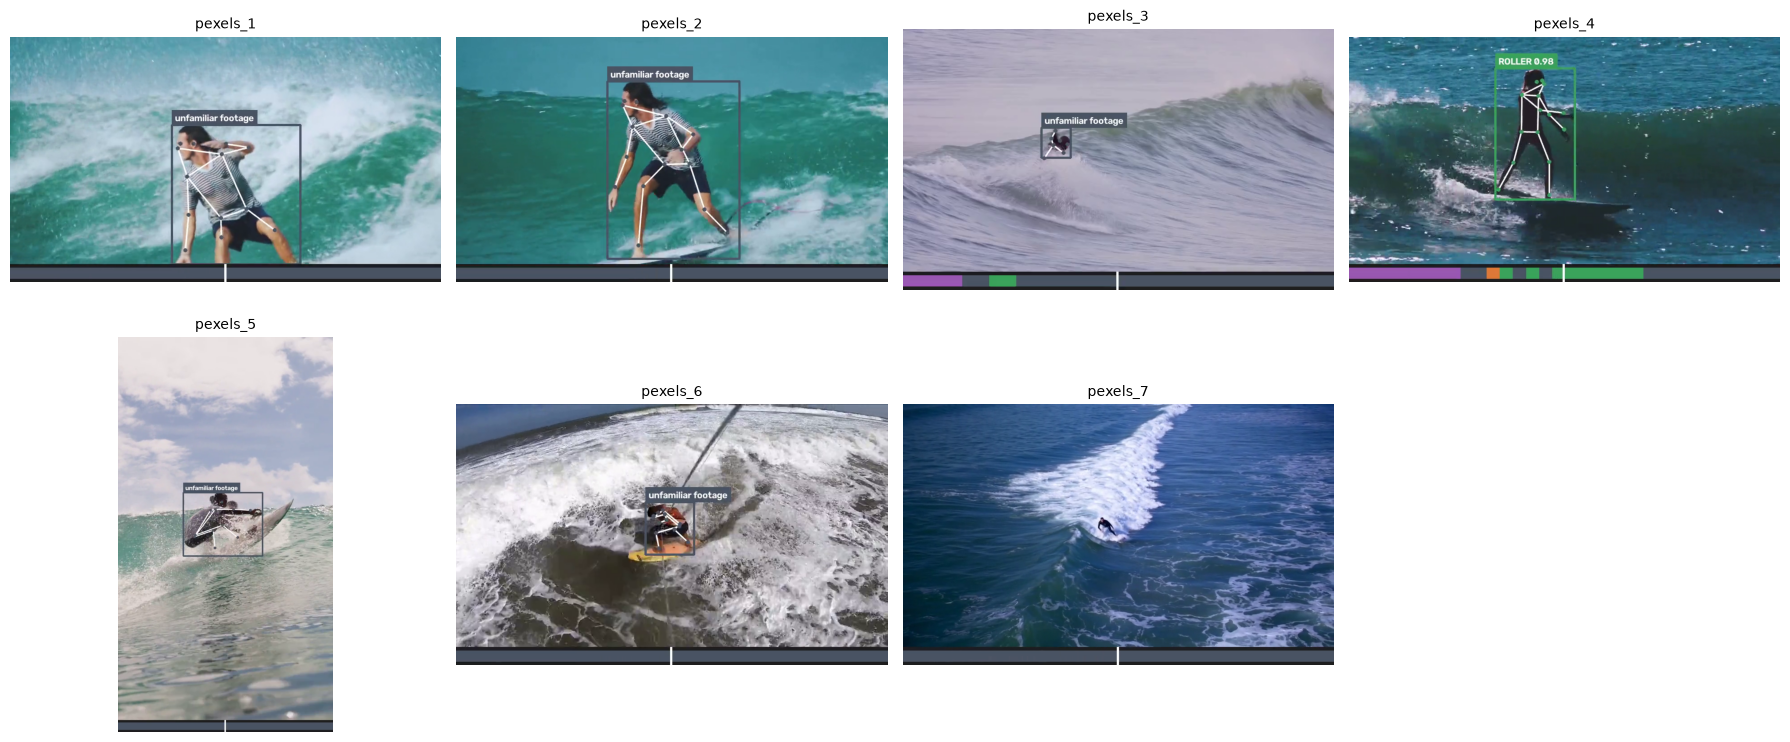

In [4]:
# Middle frame of each annotated video, to check the drawing without leaving the notebook
fig, axes = plt.subplots(2, 4, figsize=(18, 8), squeeze=False)
for ax, path in zip(axes.flat, sorted(OUT_DIR.glob("*_annotated.mp4"))):
    cap = cv2.VideoCapture(str(path))
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(cap.get(cv2.CAP_PROP_FRAME_COUNT) * 0.5))
    ok, frame = cap.read()
    cap.release()
    if ok:
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(path.stem.replace("_annotated", ""), fontsize=10)
    ax.axis("off")
for ax in axes.flat[len(VIDEOS):]:
    ax.axis("off")
plt.tight_layout()
fig.savefig(PROJECT_ROOT / "reports" / "figures" / "annotated_frames.png", dpi=120)
plt.show()

## 5. Demo montage of held-out test clips

In [5]:
import imageio_ffmpeg

from src.data.inventory import DATA_DIR
from src.models.evaluate import linear_probe

# Classifier and novelty check refit WITHOUT the test split, so every clip in the montage is from an unseen session
not_test = (splits["split"] != "test").to_numpy()
demo_probe = linear_probe().fit(X_surfer[not_test], splits.loc[not_test, "maneuver"].to_numpy())
demo_novelty = KnnNovelty().fit(X_surfer[not_test], splits.loc[not_test, "group"].to_numpy())

# 3 random test clips per maneuver, shuffled into one video at 30 fps and 640x360 (the dataset's frame size)
picked = (splits[splits["split"] == "test"].groupby("maneuver").sample(3, random_state=0)
          .sample(frac=1, random_state=0))
MONTAGE, FPS, SIZE = OUT_DIR / "test_montage.mp4", 30, (640, 360)

writer = imageio_ffmpeg.write_frames(str(MONTAGE), SIZE, fps=FPS, codec="libx264",
                                     pix_fmt_out="yuv420p", macro_block_size=2)
writer.send(None)
truth, t = [], 0.0
for _, clip in picked.iterrows():
    cap = cv2.VideoCapture(str(DATA_DIR / clip["clip"]))
    native_fps = cap.get(cv2.CAP_PROP_FPS) or FPS
    frames = []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        frames.append(frame)
    cap.release()
    # Resample to 30 fps so 60 fps clips do not turn into slow motion
    for i in np.arange(0, len(frames), native_fps / FPS).astype(int):
        writer.send(np.ascontiguousarray(cv2.cvtColor(cv2.resize(frames[i], SIZE), cv2.COLOR_BGR2RGB)))
    duration = len(frames) / native_fps
    truth.append({"maneuver": clip["maneuver"], "group": clip["group"], "start_s": t, "end_s": t + duration})
    t += duration
writer.close()
truth = pd.DataFrame(truth)
print(f"montage: {len(truth)} clips, {t:.1f}s")

montage: 12 clips, 32.9s


In [6]:
# Full pipeline on the montage, then annotated video
frames, fps = read_video(MONTAGE, SAMPLE_FPS)
windows = label_windows(frames, fps, WINDOW_S, STRIDE_S, detector, encoder, demo_probe)
windows = add_knn_distance(windows, demo_novelty)
labels, confidence = window_labels(windows, list(demo_probe.classes_), novelty_threshold=demo_novelty.threshold_)
annotate_video(MONTAGE, OUT_DIR / "test_montage_annotated.mp4", windows, labels, confidence, pose_model)

# Per clip: the most common label among windows whose center falls inside that clip
centers = ((windows["start_s"] + windows["end_s"]) / 2).to_numpy()
truth["predicted"] = [pd.Series(labels[(centers >= s) & (centers < e)]).mode().iat[0]
                      if ((centers >= s) & (centers < e)).any() else "no window"
                      for s, e in zip(truth["start_s"], truth["end_s"])]
truth["correct"] = truth["predicted"] == truth["maneuver"]
print(truth.round(1).to_string(index=False))
print(f"\n{truth['correct'].sum()} of {len(truth)} clips correct")

         maneuver  group  start_s  end_s         predicted  correct
           roller      6      0.0    2.6            roller     True
         take-off     23      2.6    5.0              none    False
cutback-frontside     23      5.0    6.9 cutback-frontside     True
         take-off     29      6.9    9.3              none    False
              360      6      9.3   12.2               360     True
           roller     28     12.2   14.8            roller     True
              360      6     14.8   17.7               360     True
           roller     29     17.7   20.3            roller     True
         take-off     28     20.3   22.8            roller    False
cutback-frontside      6     22.8   26.1 cutback-frontside     True
              360      6     26.1   30.0               360     True
cutback-frontside      6     30.0   32.9            roller    False

8 of 12 clips correct


## 6. Findings

- **Annotated output works end to end.** Each video gets the surfer's skeleton, a box colored by the current window label and a timeline bar with a cursor (`data/external/annotated/`, not versioned). The pose model draws clean skeletons on close-ups and on small contest-style surfers, and misses the tiny surfer in the top-down drone view.
- **On the Pexels videos, almost every window is labeled "unfamiliar footage"**, as expected from notebook 10: only pexels_3 and pexels_4 get maneuver labels.
- **Demo montage of held-out test clips.** 12 clips from the session-aware test split (3 per maneuver, shuffled) are joined into one 33 s video. The classifier and the novelty check are refit on train + val only, so every clip comes from an unseen session. No window is flagged as unfamiliar.
- **8 of 12 clips get the right majority label.** Three of the four errors are take-offs (2 labeled none, 1 roller) and one is a cutback labeled roller. Take-off clips are short (about 2.4 s, below the 2.8 s window), so every window that covers one also covers part of a neighboring clip, and take-off is the class the person detector finds least often (notebook 08), which pushes windows to "none".
- **This is a demonstration, not a metric.** With 12 clips one error moves the score by 8 points, and windows that straddle two clips mix maneuvers. The reference numbers are the 50-fold cross-validation results of notebooks 06–09.